# Market Monte Carlo Simulation (Python/JAX)

This notebook models the market as a batched state machine and evaluates whether timing and one-sided liquidity strategies can generate persistent, potentially unfair edge.

Source-of-truth logic is mirrored from:
- `domain/workflows/exchange.ts`
- `domain/workflows/liquidity.ts`
- `domain/aggregates/exchange.ts`

In [8]:
!pip install matplotlib
import matplotlib.pyplot as plt

In [1]:
# beginning of LLM written Code, Model: gpt-5.3-codex
from __future__ import annotations

import json
from dataclasses import dataclass
from pathlib import Path

import jax
import jax.numpy as jnp

# State layout (batched: [num_paths, NUM_FEATURES])
IDX_RESERVE_BASE = 0
IDX_RESERVE_QUOTE = 1
IDX_TOTAL_LP = 2
IDX_MARKET_STATUS = 3  # 0=pending, 1=active, 2=closed
IDX_WAS_PREV_ACTIVE = 4
IDX_TIMESTAMP_MS = 5
IDX_LOCK_UNTIL_MS = 6
IDX_LP_TOKENS_ACTOR = 7
IDX_ACTOR_CASH_QUOTE = 8
IDX_ACTOR_INV_BASE = 9
IDX_PASSIVE_CASH_QUOTE = 10
IDX_PASSIVE_INV_BASE = 11
IDX_BUY_PRESSURE_USD = 12
IDX_SELL_PRESSURE_USD = 13

NUM_FEATURES = 14
PENDING = 0
ACTIVE = 1
CLOSED = 2

MIN_LIQUIDITY_CENTS = 10_000.0  # Mirrors domain/workflows/liquidity.ts
LOCK_DURATION_MS = 15 * 24 * 60 * 60 * 1000
EPS = 1e-9


def initialize_state_batch(
    num_paths: int,
    *,
    reserve_base: float = 0.0,
    reserve_quote: float = 0.0,
    total_lp_tokens: float = 0.0,
    market_status: int = PENDING,
    was_previously_active: float = 0.0,
    actor_cash_quote: float = 100_000.0,
    actor_inventory_base: float = 0.0,
    passive_cash_quote: float = 100_000.0,
    passive_inventory_base: float = 0.0,
    start_timestamp_ms: float = 0.0,
) -> jnp.ndarray:
    state = jnp.zeros((num_paths, NUM_FEATURES), dtype=jnp.float32)
    state = state.at[:, IDX_RESERVE_BASE].set(reserve_base)
    state = state.at[:, IDX_RESERVE_QUOTE].set(reserve_quote)
    state = state.at[:, IDX_TOTAL_LP].set(total_lp_tokens)
    state = state.at[:, IDX_MARKET_STATUS].set(float(market_status))
    state = state.at[:, IDX_WAS_PREV_ACTIVE].set(was_previously_active)
    state = state.at[:, IDX_TIMESTAMP_MS].set(start_timestamp_ms)
    state = state.at[:, IDX_LOCK_UNTIL_MS].set(0.0)
    state = state.at[:, IDX_LP_TOKENS_ACTOR].set(0.0)
    state = state.at[:, IDX_ACTOR_CASH_QUOTE].set(actor_cash_quote)
    state = state.at[:, IDX_ACTOR_INV_BASE].set(actor_inventory_base)
    state = state.at[:, IDX_PASSIVE_CASH_QUOTE].set(passive_cash_quote)
    state = state.at[:, IDX_PASSIVE_INV_BASE].set(passive_inventory_base)
    return state


# quick smoke state
state0 = initialize_state_batch(
    num_paths=1000,
    reserve_base=0.0,
    reserve_quote=0.0,
    total_lp_tokens=0.0,
    market_status=PENDING,
)
state0.shape
# end of LLM written Code

(1000, 14)

In [2]:
# beginning of LLM written Code, Model: gpt-5.3-codex

def _pool_value_cents(reserve_quote: jnp.ndarray) -> jnp.ndarray:
    return 2.0 * reserve_quote


def _meets_threshold(reserve_quote: jnp.ndarray) -> jnp.ndarray:
    return _pool_value_cents(reserve_quote) >= MIN_LIQUIDITY_CENTS


def _cpmm_trade(
    reserve_base: jnp.ndarray,
    reserve_quote: jnp.ndarray,
    side: jnp.ndarray,
    order_quote_size: jnp.ndarray,
) -> tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    """
    CPMM fill approximation used for Monte Carlo transition.
    side: +1 buy base with quote, -1 sell base for quote
    returns: new_base, new_quote, executed_base
    """
    k = jnp.maximum(reserve_base * reserve_quote, EPS)
    quote_in = jnp.where(side > 0, jnp.maximum(order_quote_size, 0.0), 0.0)
    new_quote_buy = reserve_quote + quote_in
    new_base_buy = k / jnp.maximum(new_quote_buy, EPS)
    base_out_buy = jnp.maximum(reserve_base - new_base_buy, 0.0)

    quote_out_target = jnp.where(side < 0, jnp.maximum(order_quote_size, 0.0), 0.0)
    new_quote_sell = jnp.maximum(reserve_quote - quote_out_target, EPS)
    new_base_sell = k / new_quote_sell
    base_in_sell = jnp.maximum(new_base_sell - reserve_base, 0.0)

    new_base = jnp.where(side > 0, new_base_buy, new_base_sell)
    new_quote = jnp.where(side > 0, new_quote_buy, new_quote_sell)
    executed_base = jnp.where(side > 0, base_out_buy, base_in_sell)
    return new_base, new_quote, executed_base


def time_advance_event(state: jnp.ndarray, dt_ms: jnp.ndarray) -> jnp.ndarray:
    current_ts = state[:, IDX_TIMESTAMP_MS]
    return state.at[:, IDX_TIMESTAMP_MS].set(current_ts + dt_ms)


def provide_liquidity_event(
    state: jnp.ndarray,
    amount_base: jnp.ndarray,
    amount_quote: jnp.ndarray,
) -> jnp.ndarray:
    reserve_base = state[:, IDX_RESERVE_BASE]
    reserve_quote = state[:, IDX_RESERVE_QUOTE]
    total_lp = state[:, IDX_TOTAL_LP]
    status = state[:, IDX_MARKET_STATUS]
    ts = state[:, IDX_TIMESTAMP_MS]

    empty_pool = (reserve_base <= EPS) & (reserve_quote <= EPS)
    minted_empty = jnp.sqrt(jnp.maximum(amount_base * amount_quote, 0.0))
    minted_non_empty = jnp.minimum(
        amount_base * total_lp / jnp.maximum(reserve_base, EPS),
        amount_quote * total_lp / jnp.maximum(reserve_quote, EPS),
    )
    minted = jnp.where(empty_pool, minted_empty, minted_non_empty)

    new_reserve_base = reserve_base + amount_base
    new_reserve_quote = reserve_quote + amount_quote
    new_total_lp = total_lp + minted

    should_activate = (status == PENDING) & _meets_threshold(new_reserve_quote)
    new_status = jnp.where(should_activate, ACTIVE, status)
    was_prev_active = state[:, IDX_WAS_PREV_ACTIVE]
    new_was_prev_active = jnp.where(should_activate, 1.0, was_prev_active)

    lock_until = state[:, IDX_LOCK_UNTIL_MS]
    lock_if_active = ts + LOCK_DURATION_MS
    new_lock_until = jnp.where(status == ACTIVE, lock_if_active, lock_until)

    actor_lp = state[:, IDX_LP_TOKENS_ACTOR] + minted
    actor_cash = state[:, IDX_ACTOR_CASH_QUOTE] - amount_quote
    actor_inv = state[:, IDX_ACTOR_INV_BASE] - amount_base

    state = state.at[:, IDX_RESERVE_BASE].set(new_reserve_base)
    state = state.at[:, IDX_RESERVE_QUOTE].set(new_reserve_quote)
    state = state.at[:, IDX_TOTAL_LP].set(new_total_lp)
    state = state.at[:, IDX_MARKET_STATUS].set(new_status)
    state = state.at[:, IDX_WAS_PREV_ACTIVE].set(new_was_prev_active)
    state = state.at[:, IDX_LOCK_UNTIL_MS].set(new_lock_until)
    state = state.at[:, IDX_LP_TOKENS_ACTOR].set(actor_lp)
    state = state.at[:, IDX_ACTOR_CASH_QUOTE].set(actor_cash)
    state = state.at[:, IDX_ACTOR_INV_BASE].set(actor_inv)
    return state


def withdraw_liquidity_event(state: jnp.ndarray, lp_burn_fraction: jnp.ndarray) -> jnp.ndarray:
    reserve_base = state[:, IDX_RESERVE_BASE]
    reserve_quote = state[:, IDX_RESERVE_QUOTE]
    total_lp = state[:, IDX_TOTAL_LP]
    actor_lp = state[:, IDX_LP_TOKENS_ACTOR]
    status = state[:, IDX_MARKET_STATUS]

    lock_until = state[:, IDX_LOCK_UNTIL_MS]
    ts = state[:, IDX_TIMESTAMP_MS]
    unlocked = ts >= lock_until

    burn = jnp.minimum(actor_lp, jnp.maximum(lp_burn_fraction, 0.0) * actor_lp)
    burn = jnp.where(unlocked, burn, 0.0)

    share_base = burn * reserve_base / jnp.maximum(total_lp, EPS)
    share_quote = burn * reserve_quote / jnp.maximum(total_lp, EPS)

    new_reserve_base = reserve_base - share_base
    new_reserve_quote = reserve_quote - share_quote
    new_total_lp = total_lp - burn
    new_actor_lp = actor_lp - burn

    should_deactivate = (status == ACTIVE) & (~_meets_threshold(new_reserve_quote))
    new_status = jnp.where(should_deactivate, PENDING, status)

    actor_cash = state[:, IDX_ACTOR_CASH_QUOTE] + share_quote
    actor_inv = state[:, IDX_ACTOR_INV_BASE] + share_base

    state = state.at[:, IDX_RESERVE_BASE].set(new_reserve_base)
    state = state.at[:, IDX_RESERVE_QUOTE].set(new_reserve_quote)
    state = state.at[:, IDX_TOTAL_LP].set(new_total_lp)
    state = state.at[:, IDX_LP_TOKENS_ACTOR].set(new_actor_lp)
    state = state.at[:, IDX_MARKET_STATUS].set(new_status)
    state = state.at[:, IDX_ACTOR_CASH_QUOTE].set(actor_cash)
    state = state.at[:, IDX_ACTOR_INV_BASE].set(actor_inv)
    return state


def trade_event(
    state: jnp.ndarray,
    side: jnp.ndarray,
    quote_size: jnp.ndarray,
    trader_selector: jnp.ndarray,
) -> jnp.ndarray:
    reserve_base = state[:, IDX_RESERVE_BASE]
    reserve_quote = state[:, IDX_RESERVE_QUOTE]

    new_base, new_quote, executed_base = _cpmm_trade(reserve_base, reserve_quote, side, quote_size)

    actor_cash = state[:, IDX_ACTOR_CASH_QUOTE]
    actor_inv = state[:, IDX_ACTOR_INV_BASE]
    passive_cash = state[:, IDX_PASSIVE_CASH_QUOTE]
    passive_inv = state[:, IDX_PASSIVE_INV_BASE]

    quote_signed = jnp.where(side > 0, -quote_size, quote_size)
    base_signed = jnp.where(side > 0, executed_base, -executed_base)

    is_actor = trader_selector > 0
    actor_cash = actor_cash + jnp.where(is_actor, quote_signed, 0.0)
    actor_inv = actor_inv + jnp.where(is_actor, base_signed, 0.0)
    passive_cash = passive_cash + jnp.where(~is_actor, quote_signed, 0.0)
    passive_inv = passive_inv + jnp.where(~is_actor, base_signed, 0.0)

    buy_pressure = state[:, IDX_BUY_PRESSURE_USD]
    sell_pressure = state[:, IDX_SELL_PRESSURE_USD]
    buy_pressure = jnp.where(side > 0, buy_pressure + quote_size, buy_pressure)
    sell_pressure = jnp.where(side < 0, sell_pressure + quote_size, sell_pressure)

    state = state.at[:, IDX_RESERVE_BASE].set(new_base)
    state = state.at[:, IDX_RESERVE_QUOTE].set(new_quote)
    state = state.at[:, IDX_ACTOR_CASH_QUOTE].set(actor_cash)
    state = state.at[:, IDX_ACTOR_INV_BASE].set(actor_inv)
    state = state.at[:, IDX_PASSIVE_CASH_QUOTE].set(passive_cash)
    state = state.at[:, IDX_PASSIVE_INV_BASE].set(passive_inv)
    state = state.at[:, IDX_BUY_PRESSURE_USD].set(buy_pressure)
    state = state.at[:, IDX_SELL_PRESSURE_USD].set(sell_pressure)
    return state


def transition_step(state: jnp.ndarray, action: jnp.ndarray) -> tuple[jnp.ndarray, jnp.ndarray]:
    """
    action columns:
      0: dt_ms
      1: event_kind (0=trade,1=provide,2=withdraw,3=time)
      2: trade_side (+1/-1)
      3: trade_quote_size
      4: provide_base
      5: provide_quote
      6: burn_fraction
      7: trader_selector (1=actor,0=passive)
    """
    dt_ms = action[:, 0]
    kind = action[:, 1]
    trade_side = action[:, 2]
    trade_quote_size = action[:, 3]
    provide_base = action[:, 4]
    provide_quote = action[:, 5]
    burn_fraction = action[:, 6]
    trader_selector = action[:, 7]

    state = time_advance_event(state, dt_ms)

    state_trade = trade_event(state, trade_side, trade_quote_size, trader_selector)
    state_provide = provide_liquidity_event(state, provide_base, provide_quote)
    state_withdraw = withdraw_liquidity_event(state, burn_fraction)

    is_trade = kind == 0
    is_provide = kind == 1
    is_withdraw = kind == 2

    next_state = jnp.where(is_trade[:, None], state_trade, state)
    next_state = jnp.where(is_provide[:, None], state_provide, next_state)
    next_state = jnp.where(is_withdraw[:, None], state_withdraw, next_state)
    return next_state, next_state


def rollout(initial_state: jnp.ndarray, actions_t: jnp.ndarray) -> tuple[jnp.ndarray, jnp.ndarray]:
    """actions_t shape: [T, num_paths, 8]"""
    final_state, trajectory = jax.lax.scan(transition_step, initial_state, actions_t)
    return final_state, trajectory

# end of LLM written Code

In [3]:
# beginning of LLM written Code, Model: gpt-5.3-codex

def _assert_close(name: str, a: float, b: float, tol: float = 1e-4) -> None:
    if abs(float(a) - float(b)) > tol:
        raise AssertionError(f"{name} mismatch: {a} vs {b}")


def run_calibration_checks() -> dict:
    # 1) Empty-pool LP mint mirrors sqrt(base*quote)
    s = initialize_state_batch(1)
    s = provide_liquidity_event(s, jnp.array([100.0]), jnp.array([10_000.0]))
    minted_lp = float(s[0, IDX_LP_TOKENS_ACTOR])
    _assert_close("minted_lp_empty", minted_lp, (100.0 * 10_000.0) ** 0.5)

    # 2) Activation threshold mirrors min liquidity logic (2*reserve_quote >= 10000)
    status = int(s[0, IDX_MARKET_STATUS])
    if status != ACTIVE:
        raise AssertionError("market should activate after crossing threshold")

    # 3) Lock duration applies on provide into active market
    ts_before = float(s[0, IDX_TIMESTAMP_MS])
    s = provide_liquidity_event(s, jnp.array([10.0]), jnp.array([1000.0]))
    lock_until = float(s[0, IDX_LOCK_UNTIL_MS])
    _assert_close("lock_duration_ms", lock_until - ts_before, float(LOCK_DURATION_MS), tol=1.0)

    # 4) Withdraw before lock should fail (no LP burned)
    before_lp = float(s[0, IDX_LP_TOKENS_ACTOR])
    s_locked = withdraw_liquidity_event(s, jnp.array([1.0]))
    after_lp_locked = float(s_locked[0, IDX_LP_TOKENS_ACTOR])
    _assert_close("withdraw_locked_no_change", before_lp, after_lp_locked)

    # 5) Advance time and withdraw should burn LP and potentially deactivate market
    dt = jnp.array([LOCK_DURATION_MS + 1], dtype=jnp.float32)
    s = time_advance_event(s, dt)
    s = withdraw_liquidity_event(s, jnp.array([1.0]))
    after_lp_unlocked = float(s[0, IDX_LP_TOKENS_ACTOR])
    if after_lp_unlocked > 1e-6:
        raise AssertionError("withdraw should burn actor LP once unlocked")

    return {
        "minted_lp_empty": minted_lp,
        "market_status_after_initial_provide": status,
        "lock_until_ms": lock_until,
        "lp_after_locked_withdraw": after_lp_locked,
        "lp_after_unlocked_withdraw": after_lp_unlocked,
    }


calibration_report = run_calibration_checks()
calibration_report
# end of LLM written Code

{'minted_lp_empty': 1000.0,
 'market_status_after_initial_provide': 1,
 'lock_until_ms': 1296000000.0,
 'lp_after_locked_withdraw': 1100.0,
 'lp_after_unlocked_withdraw': 0.0}

In [4]:
# beginning of LLM written Code, Model: gpt-5.3-codex
@dataclass
class PolicyParams:
    trade_bias: float = 0.5
    trade_size_min: float = 25.0
    trade_size_max: float = 250.0
    one_sided_lp_entry_prob: float = 0.015
    lp_entry_base: float = 20.0
    lp_entry_quote: float = 2_000.0
    withdraw_prob_when_profitable: float = 0.05
    sell_pressure_trigger: float = 1.2
    buy_pressure_trigger: float = 1.2


@dataclass
class SimulationConfig:
    num_paths: int = 2048
    horizon_steps: int = 500
    dt_ms: float = 60_000.0
    seed: int = 7


def _sample_trade_side(key: jax.Array, params: PolicyParams, num_paths: int) -> jnp.ndarray:
    u = jax.random.uniform(key, (num_paths,))
    return jnp.where(u < params.trade_bias, 1.0, -1.0)


def _sample_trade_size(key: jax.Array, params: PolicyParams, num_paths: int) -> jnp.ndarray:
    u = jax.random.uniform(key, (num_paths,))
    return params.trade_size_min + (params.trade_size_max - params.trade_size_min) * u


def one_sided_lp_timing_policy(
    state: jnp.ndarray,
    key: jax.Array,
    params: PolicyParams,
) -> jnp.ndarray:
    num_paths = state.shape[0]
    k1, k2, k3 = jax.random.split(key, 3)

    sell_pressure = state[:, IDX_SELL_PRESSURE_USD]
    buy_pressure = state[:, IDX_BUY_PRESSURE_USD]
    pressure_ratio = (sell_pressure + 1.0) / (buy_pressure + 1.0)

    provide_roll = jax.random.uniform(k1, (num_paths,))
    should_provide = (provide_roll < params.one_sided_lp_entry_prob) & (pressure_ratio > params.sell_pressure_trigger)

    withdraw_roll = jax.random.uniform(k2, (num_paths,))
    can_withdraw = state[:, IDX_TIMESTAMP_MS] >= state[:, IDX_LOCK_UNTIL_MS]
    should_withdraw = (withdraw_roll < params.withdraw_prob_when_profitable) & can_withdraw & (
        pressure_ratio < 1.0 / params.buy_pressure_trigger
    )

    side = _sample_trade_side(k3, params, num_paths)
    quote_size = jnp.zeros((num_paths,))

    # event_kind: 0=trade, 1=provide, 2=withdraw, 3=time
    kind = jnp.full((num_paths,), 3.0)
    kind = jnp.where(should_provide, 1.0, kind)
    kind = jnp.where(should_withdraw, 2.0, kind)

    provide_base = jnp.where(should_provide, params.lp_entry_base, 0.0)
    provide_quote = jnp.where(should_provide, params.lp_entry_quote, 0.0)
    burn_fraction = jnp.where(should_withdraw, 1.0, 0.0)

    trader_selector = jnp.ones((num_paths,))

    action = jnp.stack(
        [
            jnp.zeros((num_paths,)),
            kind,
            side,
            quote_size,
            provide_base,
            provide_quote,
            burn_fraction,
            trader_selector,
        ],
        axis=1,
    )
    return action


def trade_timing_policy(
    state: jnp.ndarray,
    key: jax.Array,
    params: PolicyParams,
) -> jnp.ndarray:
    num_paths = state.shape[0]
    k1, k2 = jax.random.split(key, 2)

    sell_pressure = state[:, IDX_SELL_PRESSURE_USD]
    buy_pressure = state[:, IDX_BUY_PRESSURE_USD]
    pressure_ratio = (buy_pressure + 1.0) / (sell_pressure + 1.0)

    side = jnp.where(pressure_ratio > params.buy_pressure_trigger, 1.0, -1.0)
    random_side = _sample_trade_side(k1, params, num_paths)
    side = jnp.where(jnp.abs(pressure_ratio - 1.0) < 0.1, random_side, side)

    quote_size = _sample_trade_size(k2, params, num_paths)
    kind = jnp.zeros((num_paths,))
    provide_base = jnp.zeros((num_paths,))
    provide_quote = jnp.zeros((num_paths,))
    burn_fraction = jnp.zeros((num_paths,))
    trader_selector = jnp.ones((num_paths,))

    return jnp.stack(
        [
            jnp.zeros((num_paths,)),
            kind,
            side,
            quote_size,
            provide_base,
            provide_quote,
            burn_fraction,
            trader_selector,
        ],
        axis=1,
    )


def mixed_policy(state: jnp.ndarray, key: jax.Array, params: PolicyParams) -> jnp.ndarray:
    k1, k2, gate = jax.random.split(key, 3)
    lp_action = one_sided_lp_timing_policy(state, k1, params)
    trade_action = trade_timing_policy(state, k2, params)

    choose_trade = jax.random.uniform(gate, (state.shape[0],)) > 0.35
    # If LP action has a non-time event, keep it; otherwise choose trade by probability.
    lp_is_event = lp_action[:, 1] != 3.0
    take_lp = lp_is_event | (~choose_trade)
    return jnp.where(take_lp[:, None], lp_action, trade_action)


def make_actions(
    initial_state: jnp.ndarray,
    config: SimulationConfig,
    params: PolicyParams,
    policy_name: str,
) -> jnp.ndarray:
    key = jax.random.PRNGKey(config.seed)
    state = initial_state
    actions = []

    policy_map = {
        "one_sided_lp": one_sided_lp_timing_policy,
        "trade_timing": trade_timing_policy,
        "mixed": mixed_policy,
    }
    policy_fn = policy_map[policy_name]

    for _ in range(config.horizon_steps):
        key, step_key = jax.random.split(key)
        action = policy_fn(state, step_key, params)
        action = action.at[:, 0].set(config.dt_ms)
        state, _ = transition_step(state, action)
        actions.append(action)

    return jnp.stack(actions, axis=0)

# end of LLM written Code

In [5]:
# beginning of LLM written Code, Model: gpt-5.3-codex

def mark_to_market_equity(state: jnp.ndarray, actor: str = "actor") -> jnp.ndarray:
    reserve_base = state[:, IDX_RESERVE_BASE]
    reserve_quote = state[:, IDX_RESERVE_QUOTE]
    px = reserve_quote / jnp.maximum(reserve_base, EPS)

    if actor == "actor":
        cash = state[:, IDX_ACTOR_CASH_QUOTE]
        inv = state[:, IDX_ACTOR_INV_BASE]
        lp = state[:, IDX_LP_TOKENS_ACTOR]
    else:
        cash = state[:, IDX_PASSIVE_CASH_QUOTE]
        inv = state[:, IDX_PASSIVE_INV_BASE]
        lp = jnp.zeros_like(cash)

    total_lp = state[:, IDX_TOTAL_LP]
    lp_share = jnp.where(total_lp > EPS, lp / total_lp, 0.0)
    lp_value = lp_share * (reserve_quote + px * reserve_base)

    return cash + inv * px + lp_value


def compute_metrics(final_state: jnp.ndarray, initial_state: jnp.ndarray) -> dict:
    actor_initial = mark_to_market_equity(initial_state, actor="actor")
    actor_final = mark_to_market_equity(final_state, actor="actor")
    passive_initial = mark_to_market_equity(initial_state, actor="passive")
    passive_final = mark_to_market_equity(final_state, actor="passive")

    actor_pnl = actor_final - actor_initial
    passive_pnl = passive_final - passive_initial

    actor_mean = float(jnp.mean(actor_pnl))
    actor_std = float(jnp.std(actor_pnl) + EPS)
    actor_sharpe_like = actor_mean / actor_std

    win_rate = float(jnp.mean((actor_pnl > passive_pnl).astype(jnp.float32)))
    actor_p5 = float(jnp.percentile(actor_pnl, 5))
    actor_p95 = float(jnp.percentile(actor_pnl, 95))
    actor_max_dd_proxy = float(jnp.min(actor_pnl))

    edge_score = actor_mean + 0.25 * actor_sharpe_like + 0.1 * (win_rate - 0.5)

    fairness_flag = bool(
        (actor_mean > 0.0)
        and (actor_sharpe_like > 0.25)
        and (win_rate > 0.60)
        and (float(jnp.mean(passive_pnl)) < 0.0)
    )

    return {
        "expected_pnl_actor": actor_mean,
        "expected_pnl_passive": float(jnp.mean(passive_pnl)),
        "risk_adjusted_return_actor": actor_sharpe_like,
        "win_rate_vs_passive": win_rate,
        "tail_p5_actor": actor_p5,
        "tail_p95_actor": actor_p95,
        "max_drawdown_proxy_actor": actor_max_dd_proxy,
        "edge_score": edge_score,
        "potential_unfair_edge": fairness_flag,
    }

# end of LLM written Code

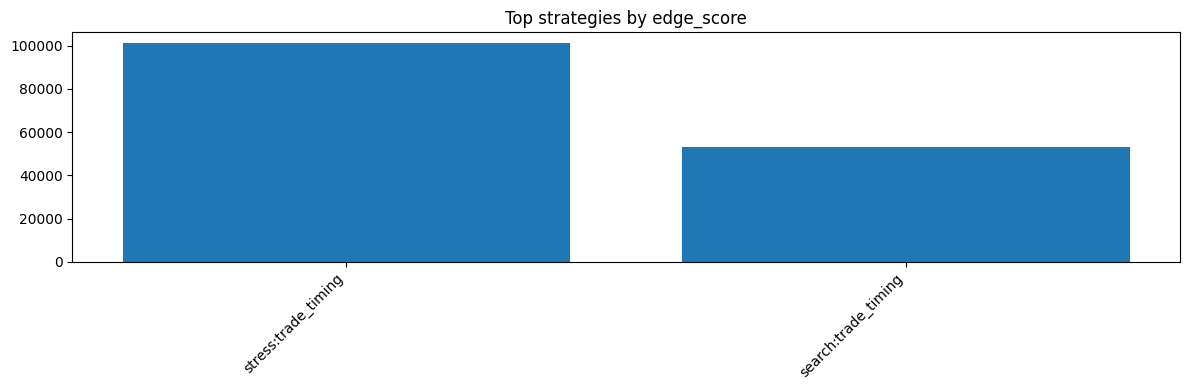

{'export_path': 'c:\\Pump the Huzz\\Bratva\\research\\monte_carlo\\results\\latest_results.json',
 'top5': [{'expected_pnl_actor': 101111.15625,
   'expected_pnl_passive': 8520.2109375,
   'risk_adjusted_return_actor': 5.135074236462789,
   'win_rate_vs_passive': 1.0,
   'tail_p5_actor': 78311.7109375,
   'tail_p95_actor': 126312.7421875,
   'max_drawdown_proxy_actor': 72588.375,
   'edge_score': 101112.49001855913,
   'potential_unfair_edge': False,
   'policy': 'trade_timing',
   'num_paths': 2048,
   'horizon_steps': 700,
   'trajectory_shape': (700, 2048, 14),
   'stage': 'stress'},
  {'expected_pnl_actor': 53123.02734375,
   'expected_pnl_passive': 5891.958984375,
   'risk_adjusted_return_actor': 3.8536914386286414,
   'win_rate_vs_passive': 1.0,
   'tail_p5_actor': 36112.29296875,
   'tail_p95_actor': 68929.71875,
   'max_drawdown_proxy_actor': 32784.171875,
   'edge_score': 53124.04076660966,
   'potential_unfair_edge': False,
   'policy': 'trade_timing',
   'num_paths': 1024,
 

In [10]:
# beginning of LLM written Code, Model: gpt-5.3-codex

def _resolve_mc_root() -> Path:
    candidates = [
        Path.cwd() / "research" / "monte_carlo",
        Path.cwd(),
        Path.cwd().parent,
    ]
    for c in candidates:
        if (c / "scenarios.json").exists() and c.name == "monte_carlo":
            return c
        if (c / "research" / "monte_carlo" / "scenarios.json").exists():
            return c / "research" / "monte_carlo"
    raise FileNotFoundError("Could not locate monte_carlo/scenarios.json from current working directory")


MC_ROOT = _resolve_mc_root()
RESULTS_DIR = MC_ROOT / "results"
SCENARIO_PATH = MC_ROOT / "scenarios.json"


def load_scenarios(path: Path = SCENARIO_PATH) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def run_single_policy(
    scenario_cfg: dict,
    policy_name: str,
    params: PolicyParams,
) -> dict:
    config = SimulationConfig(
        num_paths=int(scenario_cfg["num_paths"]),
        horizon_steps=int(scenario_cfg["horizon_steps"]),
        dt_ms=float(scenario_cfg["dt_ms"]),
        seed=int(scenario_cfg["seed"]),
    )

    initial_state = initialize_state_batch(
        config.num_paths,
        reserve_base=1000.0,
        reserve_quote=100_000.0,
        total_lp_tokens=10_000.0,
        market_status=ACTIVE,
        was_previously_active=1.0,
        actor_inventory_base=100.0,
        passive_inventory_base=100.0,
    )

    actions = make_actions(initial_state, config, params, policy_name)
    final_state, trajectory = rollout(initial_state, actions)
    m = compute_metrics(final_state, initial_state)

    m["policy"] = policy_name
    m["num_paths"] = config.num_paths
    m["horizon_steps"] = config.horizon_steps
    m["trajectory_shape"] = tuple(map(int, trajectory.shape))
    return m


def run_stage(stage_name: str, cfg: dict, policies: list[str], params: PolicyParams) -> list[dict]:
    rows = []
    for policy_name in policies:
        out = run_single_policy(cfg[stage_name], policy_name, params)
        out["stage"] = stage_name
        rows.append(out)
    return rows


def run_search_stage(cfg: dict, policies: list[str]) -> list[dict]:
    search_cfg = cfg["search"]
    rows = []
    for bias in search_cfg["trade_bias_grid"]:
        for entry_prob in search_cfg["entry_prob_grid"]:
            for withdraw_prob in search_cfg["withdraw_prob_grid"]:
                params = PolicyParams(
                    trade_bias=float(bias),
                    one_sided_lp_entry_prob=float(entry_prob),
                    withdraw_prob_when_profitable=float(withdraw_prob),
                )
                for policy_name in policies:
                    out = run_single_policy(search_cfg, policy_name, params)
                    out["stage"] = "search"
                    out["trade_bias"] = float(bias)
                    out["entry_prob"] = float(entry_prob)
                    out["withdraw_prob"] = float(withdraw_prob)
                    rows.append(out)
    return rows


def rank_results(rows: list[dict]) -> list[dict]:
    return sorted(rows, key=lambda x: x["edge_score"], reverse=True)


def export_results(rows: list[dict], path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "generated_by": "market_mcs.ipynb",
        "result_count": len(rows),
        "top10": rows[:10],
        "all_results": rows,
    }
    path.write_text(json.dumps(payload, indent=2), encoding="utf-8")


def maybe_plot_top(rows: list[dict], n: int = 10) -> None:
    try:
        import matplotlib.pyplot as plt
    except Exception:
        print("matplotlib not available; skipping plot")
        return

    top = rows[:n]
    labels = [f"{r['stage']}:{r['policy']}" for r in top]
    scores = [r["edge_score"] for r in top]

    plt.figure(figsize=(12, 4))
    plt.bar(labels, scores)
    plt.xticks(rotation=45, ha="right")
    plt.title("Top strategies by edge_score")
    plt.tight_layout()
    plt.show()


def run_all_stages() -> dict:
    cfg = load_scenarios()
    policies = cfg["policies"]
    params = PolicyParams()

    rows = []
    rows.extend(run_stage("sanity", cfg, policies, params))
    rows.extend(run_stage("stability", cfg, policies, params))
    rows.extend(run_stage("stress", cfg, policies, params))
    rows.extend(run_search_stage(cfg, policies))

    ranked = rank_results(rows)
    export_path = RESULTS_DIR / "latest_results.json"
    export_results(ranked, export_path)
    maybe_plot_top(ranked, n=12)

    return {
        "export_path": str(export_path),
        "top5": ranked[:5],
        "total_results": len(ranked),
    }


stage_report = run_all_stages()
stage_report
# end of LLM written Code